# 03 — Métricas e erros da CNN
A comparação usa os pesos da época com menor perda de validação. As previsões de treino e validação são feitas em modo de inferência, com aumento de dados desativado. Para recalcular após o treino, execute na raiz `python scripts/evaluate_validation.py --config configs/baseline_cpu.yaml`.

In [1]:
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent

# O comando de execução também funciona a partir da pasta notebooks/.
import os
os.chdir(ROOT)

import json
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Image

reports = ROOT / 'reports'
metadata = json.loads((reports / 'run_metadata.json').read_text(encoding='utf-8'))
train_metrics = json.loads((reports / 'train_metrics.json').read_text(encoding='utf-8'))
val_metrics = json.loads((reports / 'validation_metrics.json').read_text(encoding='utf-8'))
comparison = pd.DataFrame({'Treino': train_metrics, 'Validação': val_metrics}) * 100
comparison['Diferença (p.p.)'] = comparison['Treino'] - comparison['Validação']
print(f"Checkpoint da época {metadata['best_epoch']} · métricas em %")
display(comparison.round(2))

Checkpoint da época 7 · métricas em %


,Treino,Validação,Diferença (p.p.)
accuracy,68.24,66.97,1.28
precision_macro,68.54,67.33,1.21
recall_macro,68.24,66.97,1.28
f1_macro,67.38,66.17,1.21
precision_weighted,68.54,67.33,1.21
recall_weighted,68.24,66.97,1.28
f1_weighted,67.38,66.17,1.21


## Precision, Recall e F1 por classe na validação

,precision,recall,f1-score,support
cat,0.5223,0.305,0.3851,1000.0
bird,0.5875,0.500,0.5402,1000.0
dog,0.5106,0.629,0.5636,1000.0
deer,0.7285,0.483,0.5809,1000.0
airplane,0.5828,0.841,0.6885,1000.0
horse,0.6610,0.735,0.6960,1000.0
frog,0.6770,0.786,0.7274,1000.0
ship,0.8560,0.755,0.8023,1000.0
truck,0.8195,0.790,0.8045,1000.0
automobile,0.7879,0.873,0.8283,1000.0


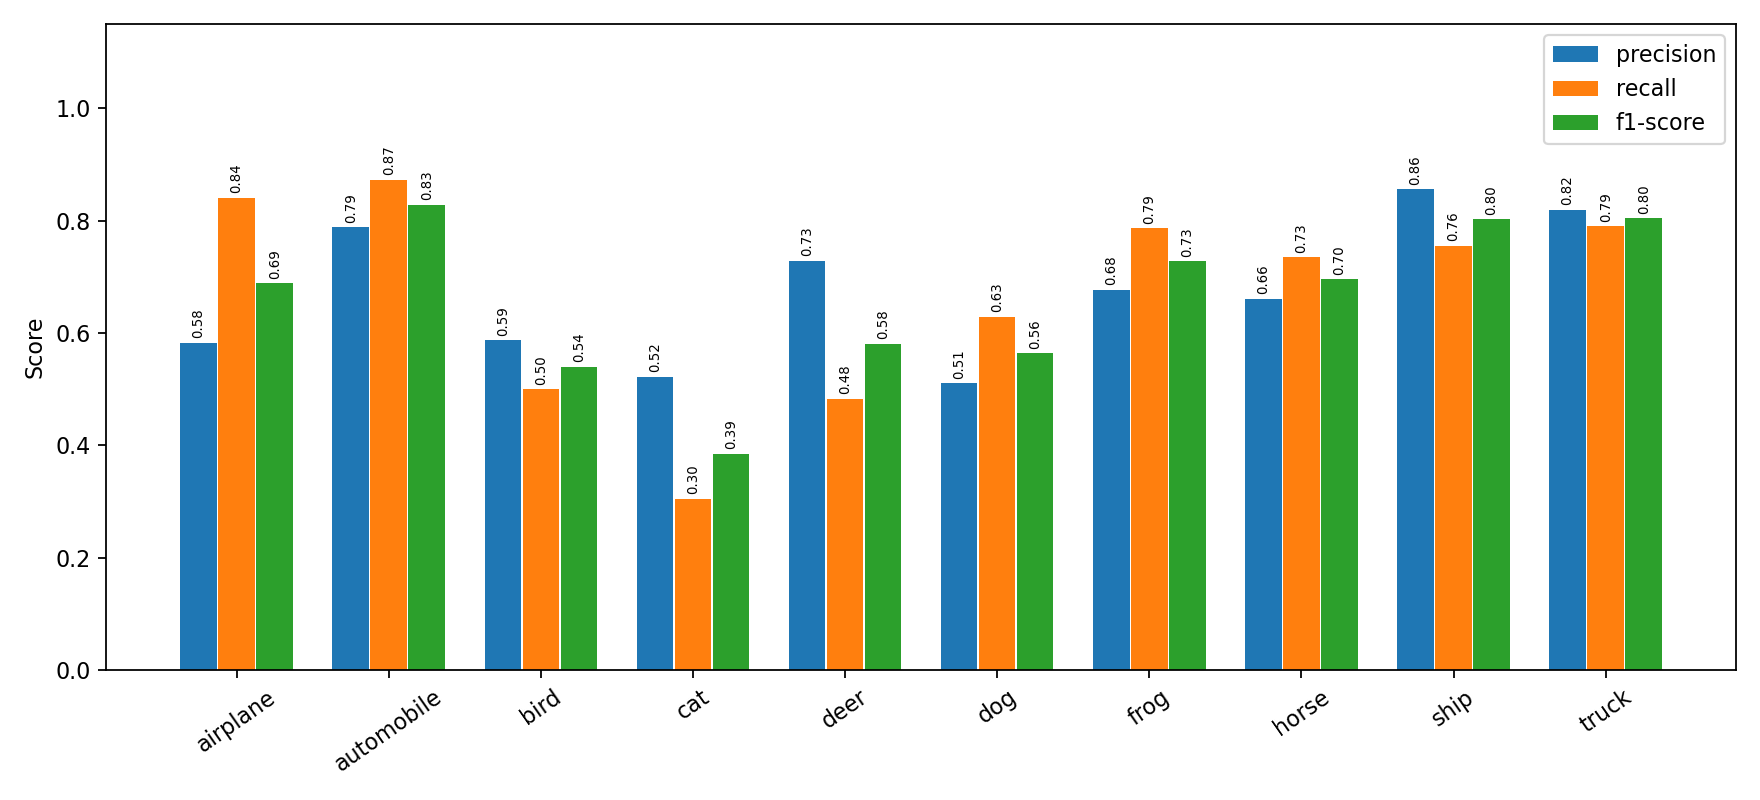

In [2]:
by_class = pd.read_csv(reports / 'validation_classification_report.csv', index_col=0)
classes = by_class.drop(index=['accuracy', 'macro avg', 'weighted avg'])
display(classes.sort_values('f1-score').round(4))
display(Image(filename=str(reports / 'figures/per_class_metrics.png')))

## Confusões e exemplos
As linhas da matriz são as classes reais e as colunas são as classes previstas. A tabela destaca os erros direcionais mais frequentes.

Total de erros: 3,303 de 10,000


,,Imagens
actual,predicted,
cat,dog,318
deer,horse,177
ship,airplane,162
bird,airplane,137
cat,frog,131
truck,automobile,124
dog,cat,115
horse,dog,98
deer,bird,84


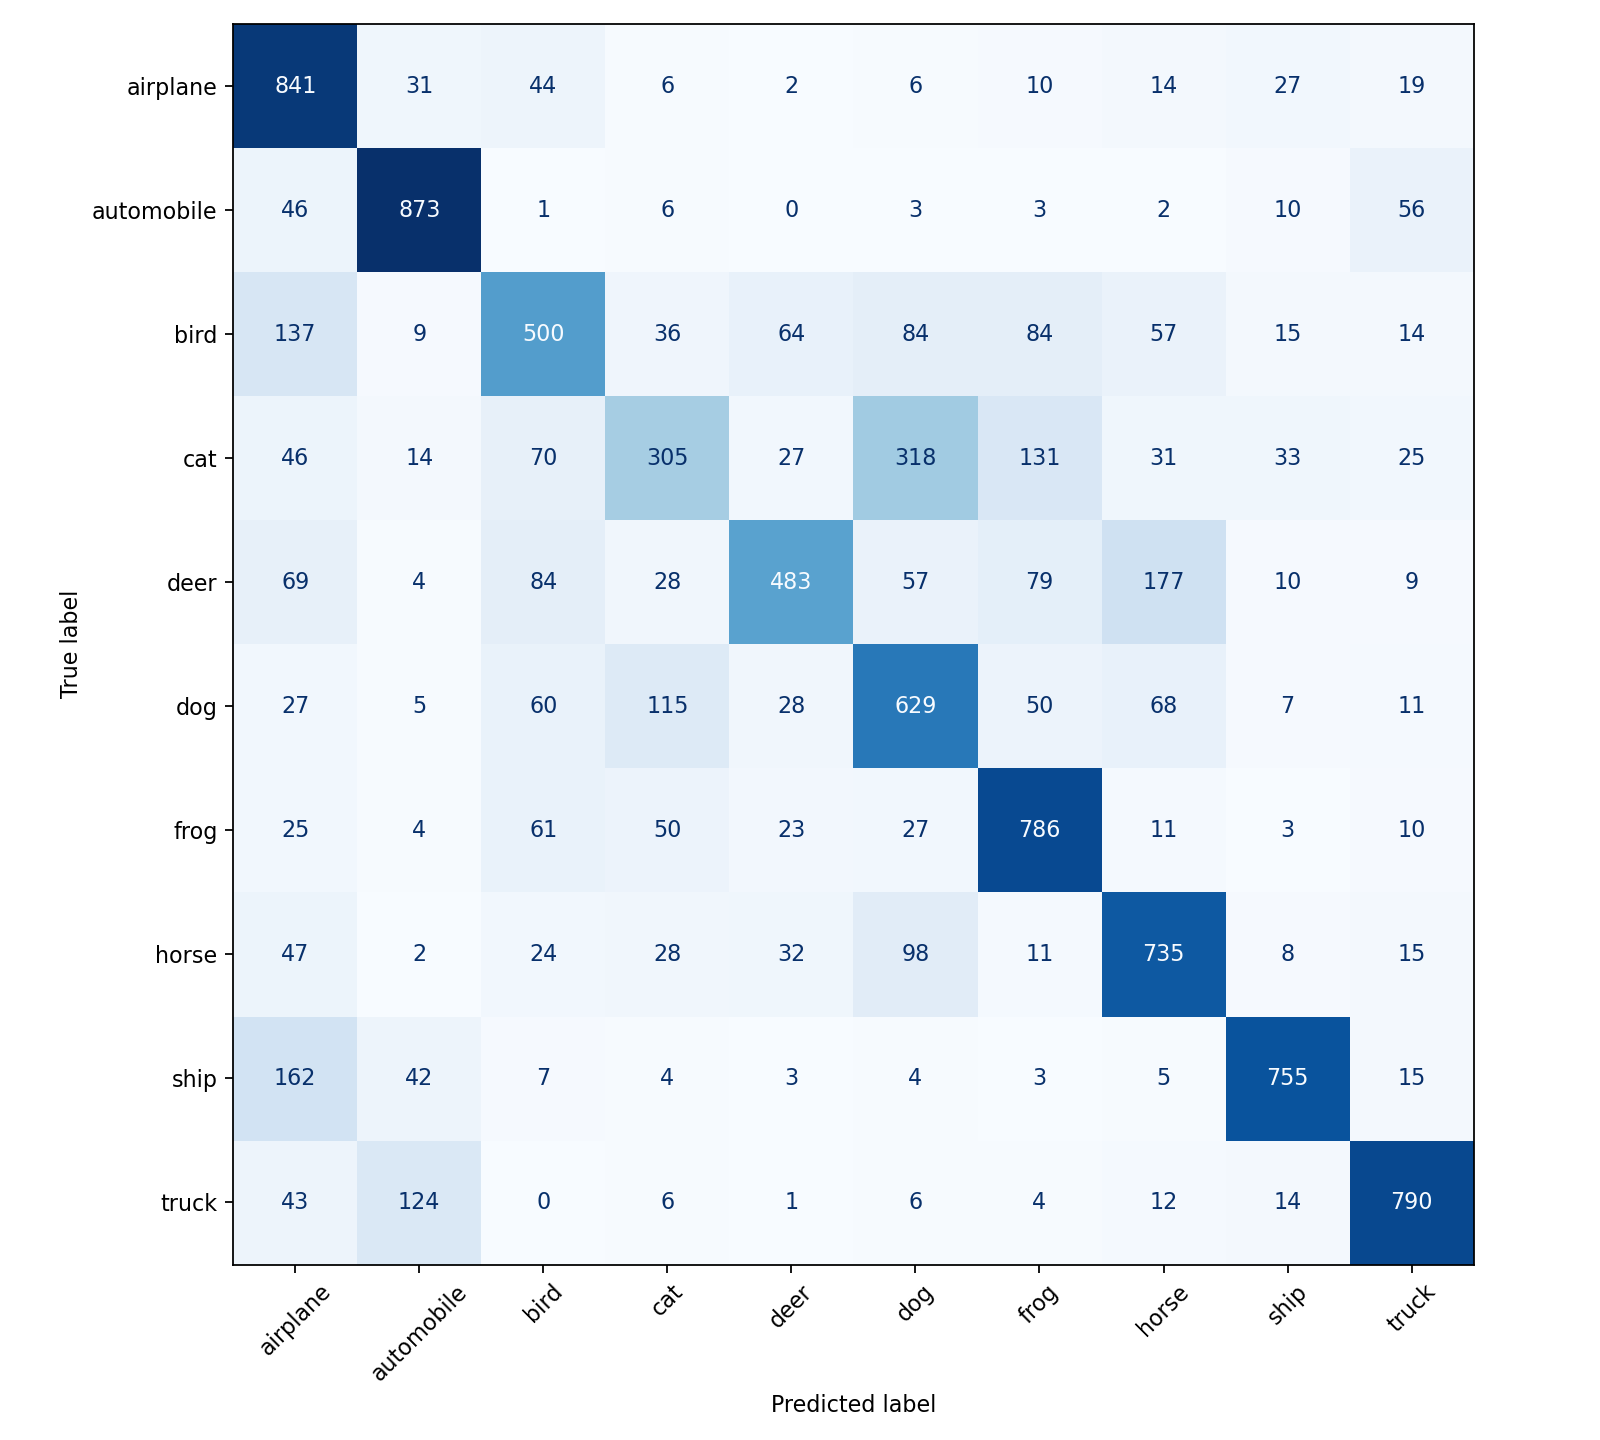

In [3]:
errors = pd.read_csv(reports / 'validation_errors.csv')
top_pairs = (errors.groupby(['actual', 'predicted']).size()
             .sort_values(ascending=False).head(10).rename('Imagens'))
print(f"Total de erros: {len(errors):,} de {metadata['validation_count']:,}")
display(top_pairs.to_frame())
display(Image(filename=str(reports / 'figures/confusion_matrix.png')))

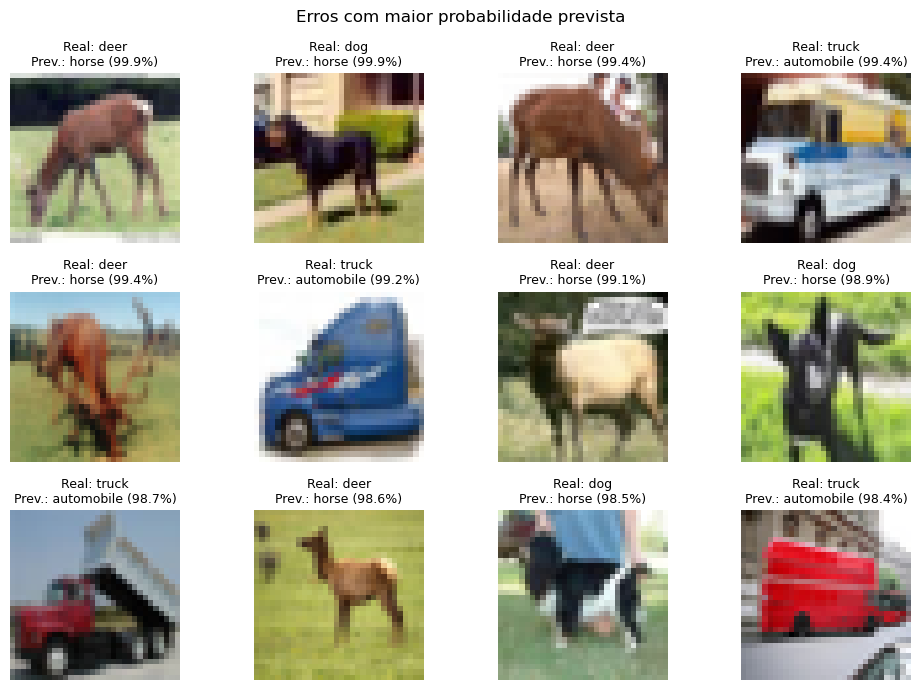

In [4]:
from cifar10_classifier.data import load_development_data

cfg = metadata['config']
_, (x_val, _) = load_development_data(cfg['validation_fraction'], cfg['seed'])
samples = errors.nlargest(12, 'confidence')
fig, axes = plt.subplots(3, 4, figsize=(10, 7))
for ax in axes.flat:
    ax.axis('off')
for ax, row in zip(axes.flat, samples.itertuples(index=False)):
    ax.imshow(x_val[row.validation_index], interpolation='nearest')
    ax.set_title(f'Real: {row.actual}\nPrev.: {row.predicted} ({row.confidence:.1%})', fontsize=9)
fig.suptitle('Erros com maior probabilidade prevista')
fig.tight_layout()
plt.show()

## Diagnóstico da validação

- **Gato** teve o menor F1 (38,51%) e recall de 30,50%. Dos 1.000 gatos, 318 foram previstos como cachorro. No sentido inverso, 115 cachorros foram previstos como gato.
- **Cervo → cavalo** (177 casos) e **navio → avião** (162 casos) vieram a seguir. Entre os erros de maior probabilidade, aparecem cervos e cães com silhuetas de quadrúpedes e caminhões enquadrados pela cabine.
- Das 3.303 previsões incorretas, 146 receberam probabilidade prevista de pelo menos 90%. A revisão visual ajuda a localizar tipos de erro que a acurácia agregada esconde.